In [1]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.datasets import cifar10
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from sklearn.metrics import confusion_matrix
import seaborn as sns
import pandas as pd
from ipywidgets import interact_manual

#資料預處理

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 795s 5us/step
訓練資料形狀:(50000, 32, 32, 3), 訓練答案形狀:(50000, 1)
測試資料形狀:(10000, 32, 32, 3), 測試答案形狀:(10000, 1)


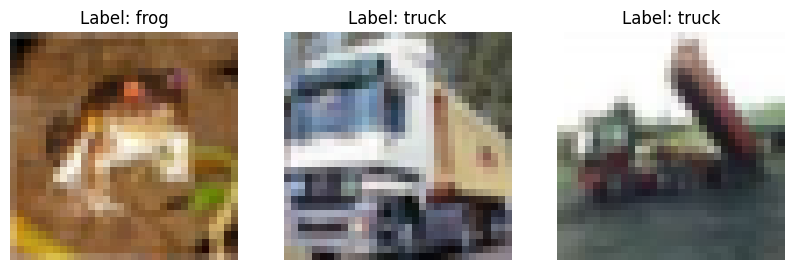

In [2]:
(x_train, y_train), (x_test, y_test) = cifar10.load_data()
print(f"訓練資料形狀:{x_train.shape}, 訓練答案形狀:{y_train.shape}")
print(f"測試資料形狀:{x_test.shape}, 測試答案形狀:{y_test.shape}")
#正規化
x_Train= x_train.astype("float32") /255.0
x_Test= x_test.astype("float32") /255.0

#One-hot編碼
y_train_onehot = to_categorical(y_train, 10)
y_test_onehot = to_categorical(y_test, 10)

#訓練資料圖片、label名稱
class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
plt.figure(figsize=(10, 3))
for i in range(3):
    plt.subplot(1, 3, i + 1)
    plt.imshow(x_train[i])
    label_idx = y_train[i][0]
    plt.title(f"Label: {class_names[label_idx]}")
    plt.axis('off')
plt.show()

#建立神經網路模型

In [3]:
model = Sequential([

  Conv2D(32, (3, 3), activation='relu', padding='same', input_shape=(32, 32, 3)),
  #input shape: (128, 32, 32, 3)
  #第一卷積層output shape: (128, 32, 32, 32)
  #參數個數: (3*3*3+1)*32 = 896

  MaxPooling2D((2, 2)),
  #第一池化層output shape: (128, 16, 16, 32)
  #參數個數: 0


  Conv2D(64, (3, 3), activation='relu', padding='same'),
  #第二卷積層output shape: (128, 16, 16, 64)
  #參數個數: (3*3*32+1)*64 = 18496

  MaxPooling2D((2, 2)),
  #第二池化層output shape: (128, 8, 8, 64)
  #參數個數: 0


  Conv2D(64, (3, 3), activation='relu', padding='same'),
  #第三卷積層output shape: (128, 8, 8, 64)
  #參數個數: (3*3*64+1)*64 = 36928


  #展平與全連接層
  Flatten(),
  #output shape: (128,4096)
  #參數個數:0
  Dense(64, activation='relu'),
  #output shape: (128,64)
  #參數個數: (4096+1)*64=262208
  Dense(10, activation='softmax')
  #output shape: (128,10)
  #參數個數: (64+1)*10=650
])
model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 8, 8, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       262,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 319,178 (1.22 MB)

 Trainable params: 319,178 (1.22 MB)

 Non-trainable params: 0 (0.00 B)

#訓練神經網路模型

In [4]:
#input shape: (128, 32, 32, 3)
#第一卷積層output shape: (128, 32, 32, 32)
#參數個數: (3*3*3+1)*32 = 896
#第一池化層output shape: (128, 16, 16, 32)
#參數個數: 0

#第二卷積層output shape: (128, 16, 16, 64)
#參數個數: (3*3*32+1)*64 = 18496

#第二池化層output shape: (128, 8, 8, 64)
#參數個數: 0

#第三卷積層output shape: (128, 8, 8, 64)
#參數個數: (3*3*64+1)*64 = 36928

#展平層output shape: (128,4096)
#參數個數:0

#全連接層output shape: (128,64)
#參數個數: (4096+1)*64=262208

#輸出層output shape: (128,10)
#參數個數: (64+1)*10=650


model.compile(loss='categorical_crossentropy',
      optimizer='adam',metrics=['accuracy'])

train_history = model.fit(x_Train, y_train_onehot,validation_split=0.2,
          epochs=20, batch_size=128)

Epoch 1/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 85s 266ms/step - accuracy: 0.4238 - loss: 1.5828 - val_accuracy: 0.5195 - val_loss: 1.3502
Epoch 2/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 88s 280ms/step - accuracy: 0.5800 - loss: 1.1892 - val_accuracy: 0.5874 - val_loss: 1.1705
Epoch 3/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 135s 257ms/step - accuracy: 0.6348 - loss: 1.0373 - val_accuracy: 0.6588 - val_loss: 0.9785
Epoch 4/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 81s 257ms/step - accuracy: 0.6829 - loss: 0.9071 - val_accuracy: 0.6752 - val_loss: 0.9344
Epoch 5/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 82s 261ms/step - accuracy: 0.7120 - loss: 0.8274 - val_accuracy: 0.6863 - val_loss: 0.8954
Epoch 6/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 81s 260ms/step - accuracy: 0.7347 - loss: 0.7663 - val_accuracy: 0.7140 - val_loss: 0.8452
Epoch 7/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 82s 261ms/step - accuracy: 0.7514 - loss: 0.7103 - val_accuracy: 0.7159 - val_loss: 0.8373
Epoch 8/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 86s 275ms/step - accuracy: 0.7725 - loss: 

#以折線圖顯示訓練過程

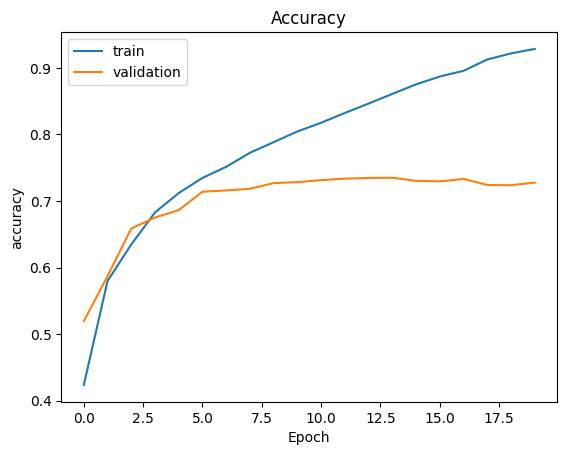

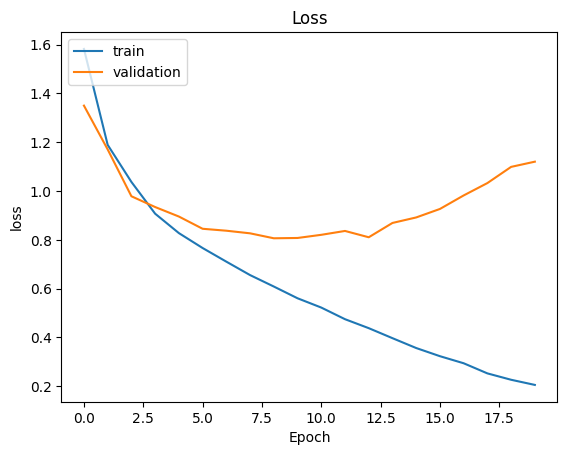

In [5]:
def show_train_history(name,train_history,train,validation):
    plt.plot(train_history.history[train])
    plt.plot(train_history.history[validation])
    plt.title(name)
    plt.ylabel(train)
    plt.xlabel('Epoch')
    plt.legend(['train', 'validation'], loc='upper left')
    plt.show()
#準確率
show_train_history("Accuracy",train_history,'accuracy','val_accuracy')
#損失誤差
show_train_history("Loss",train_history,'loss','val_loss')

#評估模型準確率

In [6]:
test_acc = model.evaluate(x_Test, y_test_onehot)
print(f"測試資料集準確率(Accuracy): {test_acc[1]}")

313/313 ━━━━━━━━━━━━━━━━━━━━ 7s 24ms/step - accuracy: 0.7221 - loss: 1.1715
測試資料集準確率(Accuracy): 0.722100019454956


#進行預測

313/313 ━━━━━━━━━━━━━━━━━━━━ 6s 18ms/step


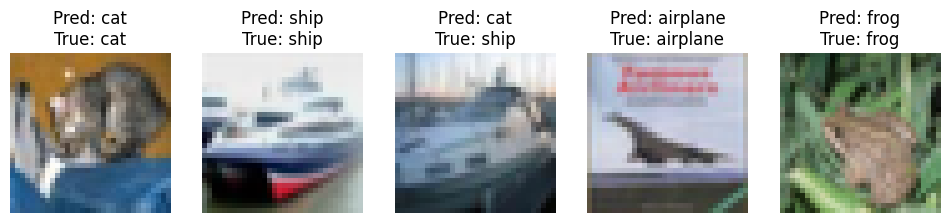

In [7]:
predictions = model.predict(x_Test)
pred_labels = np.argmax(predictions, axis=1)
true_labels = y_test.flatten()

plt.figure(figsize=(12, 4))
for i in range(5):
    plt.subplot(1, 5, i + 1)
    plt.imshow(x_test[i])
    p_name = class_names[pred_labels[i]]
    t_name = class_names[true_labels[i]]
    plt.title(f"Pred: {p_name}\nTrue: {t_name}")
    plt.axis('off')
plt.show()

#混淆矩陣呈現預測結果

In [8]:
prediction = np.argmax(model.predict(x_Test), axis=1)

y_test_names = [class_names[i] for i in y_test.flatten()]
prediction_names = [class_names[i] for i in prediction]

pd.crosstab(pd.Series(y_test_names, name='實際答案'),
            pd.Series(prediction_names, name='模型預測'))

313/313 ━━━━━━━━━━━━━━━━━━━━ 7s 23ms/step


模型預測,airplane,automobile,bird,cat,deer,dog,frog,horse,ship,truck
實際答案,,,,,,,,,,
airplane,758,17,52,23,21,13,4,20,65,27
automobile,15,846,5,16,6,7,6,6,24,69
bird,56,3,618,79,53,72,36,59,14,10
cat,18,5,68,549,56,174,35,67,16,12
deer,17,4,83,72,618,40,38,112,10,6
dog,13,2,43,167,37,629,16,78,9,6
frog,9,9,55,100,34,26,743,12,11,1
horse,2,3,29,33,40,43,1,839,7,3
ship,53,31,21,14,10,10,4,7,834,16


#儲存完整模型

In [9]:
model.save('hw4-1_cifar10_model.keras')

#測試圖片預測結果

In [10]:
def test_prediction(idx):
    plt.figure(figsize=(3, 3))
    plt.imshow(x_test[idx])
    plt.axis('off')
    plt.show()

    pred_class = class_names[pred_labels[idx]]
    true_class = class_names[true_labels[idx]]
    print(f"模型預測結果: {pred_class}")
    print(f"實際真實標籤: {true_class}")

interact_manual(test_prediction, idx=(0, len(x_test)-1))

interactive(children=(IntSlider(value=4999, description='idx', max=9999), Button(description='Run Interact', s…

<function __main__.test_prediction(idx)>